# Coffee Quality — Exploratory Data Analysis & Preprocessing

Notebook ini membahas eksplorasi dan preprocessing dataset **Coffee Quality Institute (CQI)**, berisi hasil uji cita rasa (*cupping*) **1.311 sampel kopi Arabika** dari 36 negara, termasuk Indonesia.

Dataset ini dipilih karena datanya "kotor" dengan cara yang realistis:
- Ketinggian kebun ditulis bebas: `"1.300 msnm"`, `"de 1600 a 1950"`, `"2800 ft"`, bahkan `"190164"`.
- Tahun panen berisi `"2013/2014"`, `"Mayo a Julio"`, `"4T/10"`, sampai `"TEST"`.
- Berat karung campur satuan `kg` dan `lbs`.
- Ada kolom duplikat, kolom satu nilai, dan sampel dengan skor 0.

**Tujuan**
1. Memahami struktur dan karakteristik dataset.
2. Menganalisis missing values dan duplikasi.
3. Memvisualisasikan distribusi data (histogram, boxplot, QQ plot).
4. Mengidentifikasi kandidat outlier dengan metode IQR.
5. Melakukan preprocessing dan memvalidasi hasilnya.

**Sumber data:** Coffee Quality Institute, dikumpulkan oleh James LeDoux — [github.com/jldbc/coffee-quality-database](https://github.com/jldbc/coffee-quality-database) (juga tersedia di Kaggle: *Coffee Quality database from CQI*).

## 1. Import Library

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 100

## 2. Memuat Data

In [2]:
df_raw = pd.read_csv('coffee_quality.csv')
df = df_raw.copy()   # data asli disimpan, semua pengolahan dilakukan di salinan
print('Ukuran data:', df.shape)
df.head()

Ukuran data: (1311, 44)


,Unnamed: 0,Species,Owner,Country.of.Origin,Farm.Name,Lot.Number,Mill,ICO.Number,Company,Altitude,Region,Producer,Number.of.Bags,Bag.Weight,In.Country.Partner,Harvest.Year,Grading.Date,Owner.1,Variety,Processing.Method,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean.Cup,Sweetness,Cupper.Points,Total.Cup.Points,Moisture,Category.One.Defects,Quakers,Color,Category.Two.Defects,Expiration,Certification.Body,Certification.Address,Certification.Contact,unit_of_measurement,altitude_low_meters,altitude_high_meters,altitude_mean_meters
0,1,Arabica,metad plc,Ethiopia,metad plc,NaN,metad plc,2014/2015,metad agricultural developmet plc,1950-2200,guji-hambela,METAD PLC,300,60 kg,METAD Agricultural Development plc,2014,"April 4th, 2015",metad plc,NaN,Washed / Wet,8.67,8.83,8.67,8.75,8.50,8.42,10.0,10.0,10.0,8.75,90.58,0.12,0,0.0,Green,0,"April 3rd, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1950.0,2200.0,2075.0
1,2,Arabica,metad plc,Ethiopia,metad plc,NaN,metad plc,2014/2015,metad agricultural developmet plc,1950-2200,guji-hambela,METAD PLC,300,60 kg,METAD Agricultural Development plc,2014,"April 4th, 2015",metad plc,Other,Washed / Wet,8.75,8.67,8.50,8.58,8.42,8.42,10.0,10.0,10.0,8.58,89.92,0.12,0,0.0,Green,1,"April 3rd, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1950.0,2200.0,2075.0
2,3,Arabica,grounds for health admin,Guatemala,"san marcos barrancas ""san cristobal cuch",NaN,NaN,NaN,NaN,1600 - 1800 m,NaN,NaN,5,1,Specialty Coffee Association,NaN,"May 31st, 2010",Grounds for Health Admin,Bourbon,NaN,8.42,8.50,8.42,8.42,8.33,8.42,10.0,10.0,10.0,9.25,89.75,0.00,0,0.0,NaN,0,"May 31st, 2011",Specialty Coffee Association,36d0d00a3724338ba7937c52a378d085f2172daa,0878a7d4b9d35ddbf0fe2ce69a2062cceb45a660,m,1600.0,1800.0,1700.0
3,4,Arabica,yidnekachew dabessa,Ethiopia,yidnekachew dabessa coffee plantation,NaN,wolensu,NaN,yidnekachew debessa coffee plantation,1800-2200,oromia,Yidnekachew Dabessa Coffee Plantation,320,60 kg,METAD Agricultural Development plc,2014,"March 26th, 2015",Yidnekachew Dabessa,NaN,Natural / Dry,8.17,8.58,8.42,8.42,8.50,8.25,10.0,10.0,10.0,8.67,89.00,0.11,0,0.0,Green,2,"March 25th, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1800.0,2200.0,2000.0
4,5,Arabica,metad plc,Ethiopia,metad plc,NaN,metad plc,2014/2015,metad agricultural developmet plc,1950-2200,guji-hambela,METAD PLC,300,60 kg,METAD Agricultural Development plc,2014,"April 4th, 2015",metad plc,Other,Washed / Wet,8.25,8.50,8.25,8.50,8.42,8.33,10.0,10.0,10.0,8.58,88.83,0.12,0,0.0,Green,2,"April 3rd, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1950.0,2200.0,2075.0


## 3. Memahami Struktur Data

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1311 entries, 0 to 1310
Data columns (total 44 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             1311 non-null   int64  
 1   Species                1311 non-null   str    
 2   Owner                  1304 non-null   str    
 3   Country.of.Origin      1310 non-null   str    
 4   Farm.Name              955 non-null    str    
 5   Lot.Number             270 non-null    str    
 6   Mill                   1001 non-null   str    
 7   ICO.Number             1163 non-null   str    
 8   Company                1102 non-null   str    
 9   Altitude               1088 non-null   str    
 10  Region                 1254 non-null   str    
 11  Producer               1081 non-null   str    
 12  Number.of.Bags         1311 non-null   int64  
 13  Bag.Weight             1311 non-null   str    
 14  In.Country.Partner     1311 non-null   str    
 15  Harvest.Year   

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,1311.0,656.000763,378.598733,1.0,328.50,656.00,983.50,1312.00
Number.of.Bags,1311.0,153.887872,129.733734,0.0,14.50,175.00,275.00,1062.00
Aroma,1311.0,7.563806,0.378666,0.0,7.42,7.58,7.75,8.75
Flavor,1311.0,7.518070,0.399979,0.0,7.33,7.58,7.75,8.83
Aftertaste,1311.0,7.397696,0.405119,0.0,7.25,7.42,7.58,8.67
Acidity,1311.0,7.533112,0.381599,0.0,7.33,7.50,7.75,8.75
Body,1311.0,7.517727,0.359213,0.0,7.33,7.50,7.67,8.58
Balance,1311.0,7.517506,0.406316,0.0,7.33,7.50,7.75,8.75
Uniformity,1311.0,9.833394,0.559343,0.0,10.00,10.00,10.00,10.00
Clean.Cup,1311.0,9.833120,0.771350,0.0,10.00,10.00,10.00,10.00


**Catatan awal:**
- Kolom pertama (`Unnamed: 0`) hanya nomor urut, bukan informasi.
- `Altitude`, `Bag.Weight`, `Harvest.Year`, `Grading.Date`, dan `Expiration` bertipe teks, padahal isinya angka/tanggal → perlu dikonversi.
- `Total.Cup.Points` punya nilai minimum **0**, padahal skor kopi normal sekitar 80-an → patut dicurigai.
- Dataset ini sudah menyertakan kolom bantu `altitude_low_meters`, `altitude_high_meters`, dan `altitude_mean_meters`. Kita **tidak akan memakainya** untuk mengolah ketinggian; kita olah sendiri dari kolom `Altitude` asli, lalu kolom bantu dipakai sebagai pembanding saat validasi.

In [5]:
# Kolom yang isinya hanya satu nilai tidak memberi informasi
print(df.nunique().sort_values().head(5))

Species                1
unit_of_measurement    2
Color                  3
Processing.Method      5
Sweetness              8
dtype: int64


## 4. Analisis Missing Values

In [6]:
missing = pd.DataFrame({
    'jumlah': df.isna().sum(),
    'persen': (df.isna().mean() * 100).round(2)
})
missing = missing[missing['jumlah'] > 0].sort_values('persen', ascending=False)
missing

,jumlah,persen
Lot.Number,1041,79.41
Farm.Name,356,27.15
Mill,310,23.65
Color,267,20.37
Producer,230,17.54
altitude_high_meters,227,17.32
altitude_low_meters,227,17.32
altitude_mean_meters,227,17.32
Altitude,223,17.01
Company,209,15.94


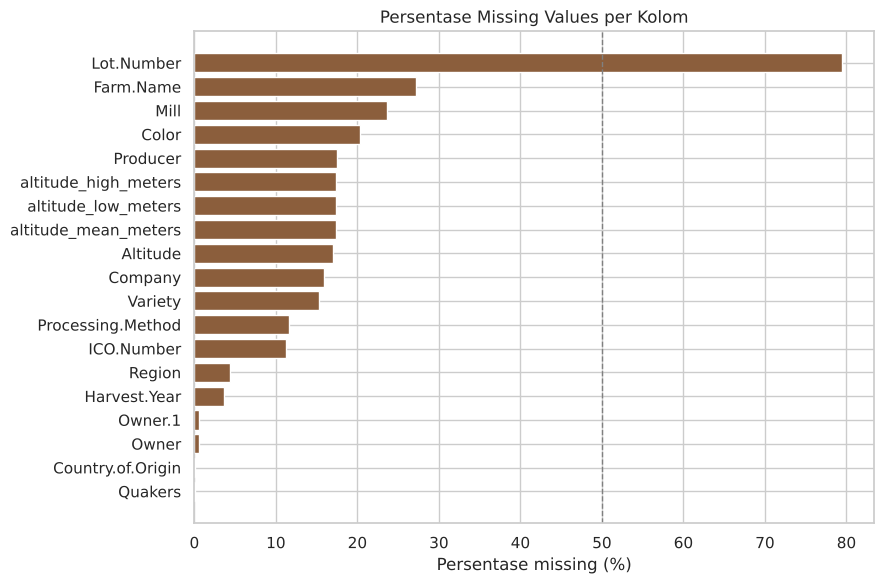

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(missing.index[::-1], missing['persen'][::-1], color='#8B5E3C')
ax.axvline(50, color='gray', ls='--', lw=1)
ax.set_xlabel('Persentase missing (%)')
ax.set_title('Persentase Missing Values per Kolom')
plt.tight_layout(); plt.show()

**Interpretasi:**
- `Lot.Number` hilang hampir 80% → lebih baik dihapus.
- Kolom identitas seperti `Farm.Name`, `Mill`, `Producer`, `Company` banyak kosong, tapi wajar karena tidak semua penjual mencantumkannya. Akan diisi `"Unknown"`, bukan dihapus.
- Kolom penting untuk analisis: `Altitude` (±17%), `Variety` (±15%), `Processing.Method` (±12%), `Color` (±20%).
- Missing values tersembunyi juga ada: nilai teks seperti `"mmm"` atau `"TEST"` di `Harvest.Year` tidak terhitung sebagai NaN, tapi sebenarnya data tidak valid.

## 5. Analisis Duplikasi

In [8]:
print('Baris duplikat (semua kolom)           :', df.duplicated().sum())
print('Baris duplikat (tanpa kolom nomor urut):', df.drop(columns='Unnamed: 0').duplicated().sum())

Baris duplikat (semua kolom)           : 0
Baris duplikat (tanpa kolom nomor urut): 0


In [9]:
# Cek kolom yang isinya kembar: Owner vs Owner.1
sama = (df['Owner'].str.lower() == df['Owner.1'].str.lower())
print(f'Owner sama dengan Owner.1 (abaikan huruf besar/kecil): {sama.sum()} dari {df["Owner"].notna().sum()} baris')
df.loc[~sama & df['Owner'].notna(), ['Owner', 'Owner.1']].head()

Owner sama dengan Owner.1 (abaikan huruf besar/kecil): 1298 dari 1304 baris


,Owner,Owner.1
219,"ceca, s.a.","CECA,S.A."
392,federacion nacional de cafeteros,Federación Nacional de Cafeteros
734,klem organics,KlemOrganics
919,"lin, che-hao krude 林哲豪","Lin, Che-Hao Krude 林哲豪\n"
961,klem organics,KlemOrganics


**Interpretasi:** tidak ada baris duplikat, tetapi ada **kolom duplikat**: `Owner.1` hampir selalu sama dengan `Owner`, hanya beda huruf besar/kecil atau karakter khusus. `Owner.1` akan dihapus.

## 6. Visualisasi Distribusi Data

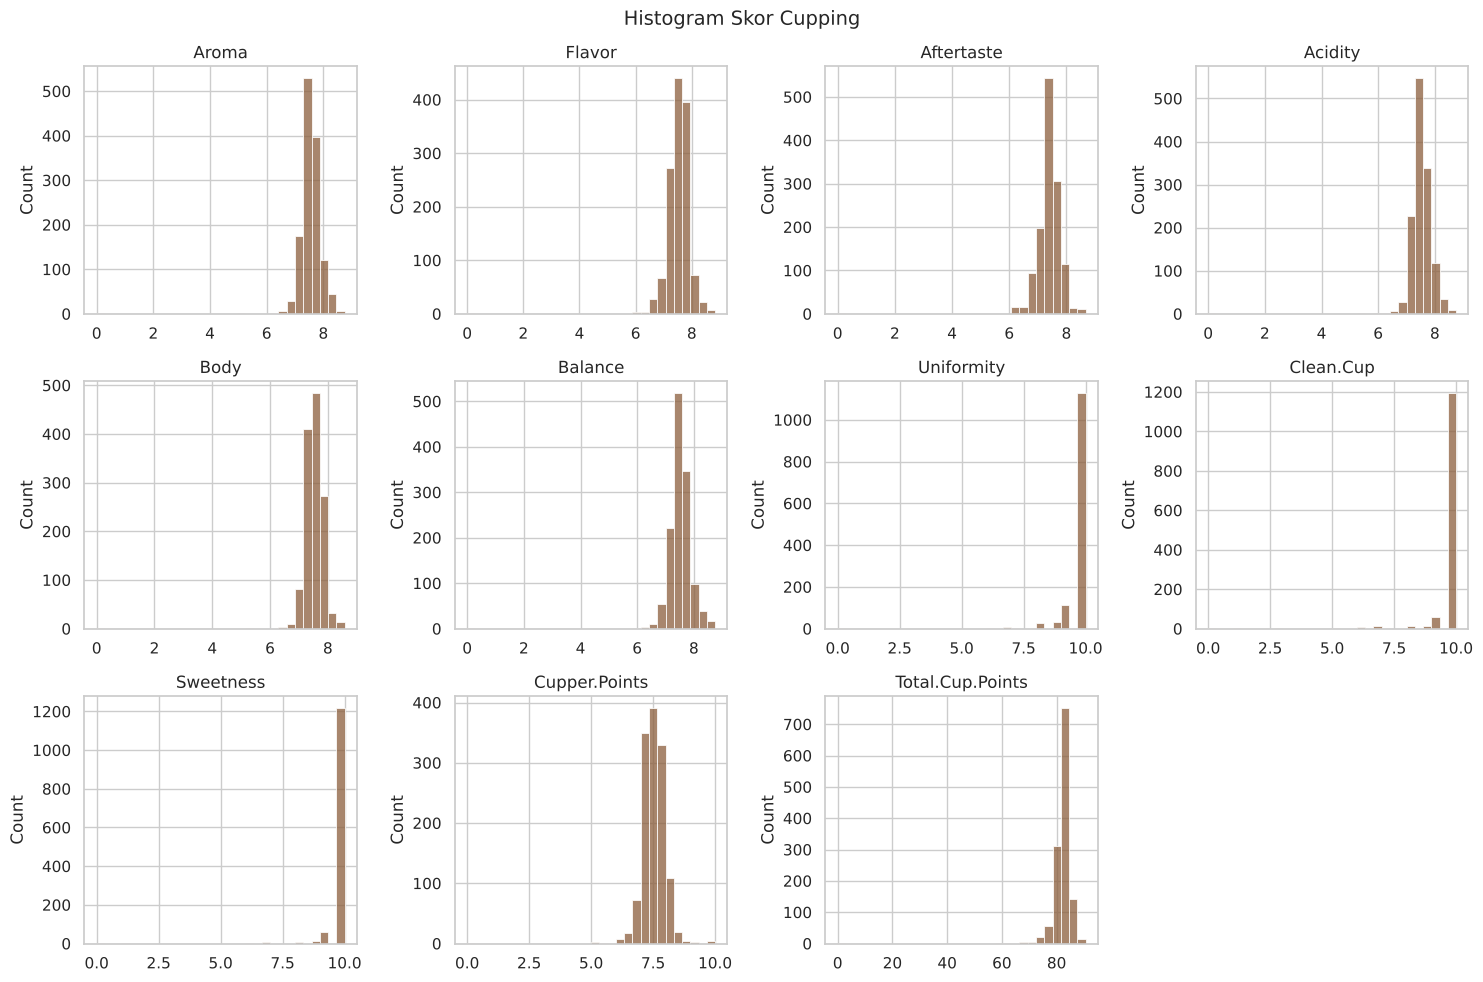

In [10]:
skor = ['Aroma', 'Flavor', 'Aftertaste', 'Acidity', 'Body', 'Balance',
        'Uniformity', 'Clean.Cup', 'Sweetness', 'Cupper.Points', 'Total.Cup.Points']

fig, axes = plt.subplots(3, 4, figsize=(15, 10))
for ax, col in zip(axes.flat, skor):
    sns.histplot(df[col], bins=30, ax=ax, color='#8B5E3C')
    ax.set_title(col)
    ax.set_xlabel('')
axes.flat[-1].axis('off')
plt.suptitle('Histogram Skor Cupping', fontsize=14)
plt.tight_layout(); plt.show()

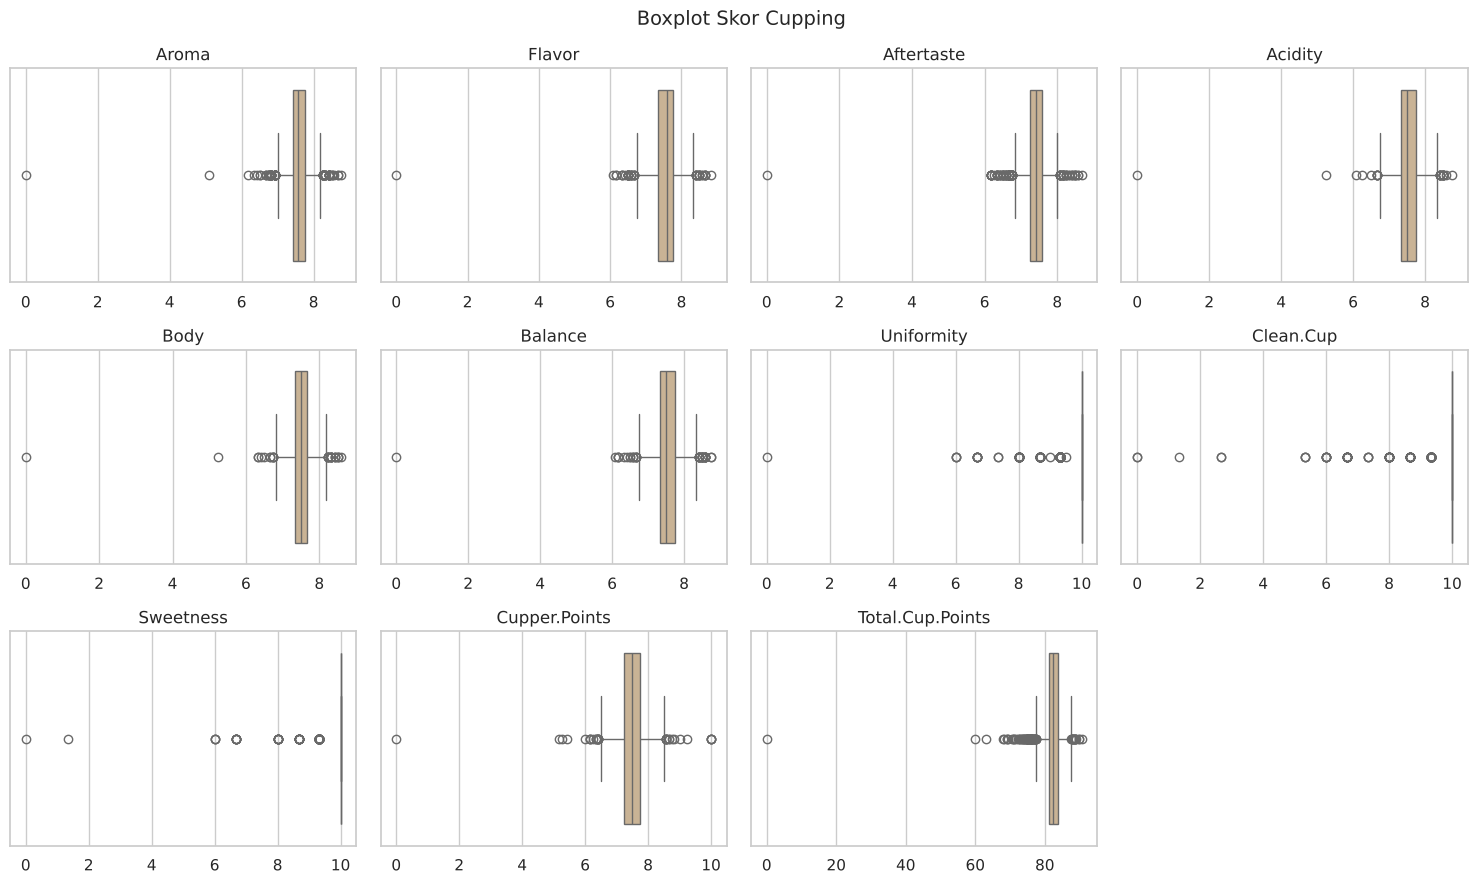

In [11]:
fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for ax, col in zip(axes.flat, skor):
    sns.boxplot(x=df[col], ax=ax, color='#D2B48C')
    ax.set_title(col)
    ax.set_xlabel('')
axes.flat[-1].axis('off')
plt.suptitle('Boxplot Skor Cupping', fontsize=14)
plt.tight_layout(); plt.show()

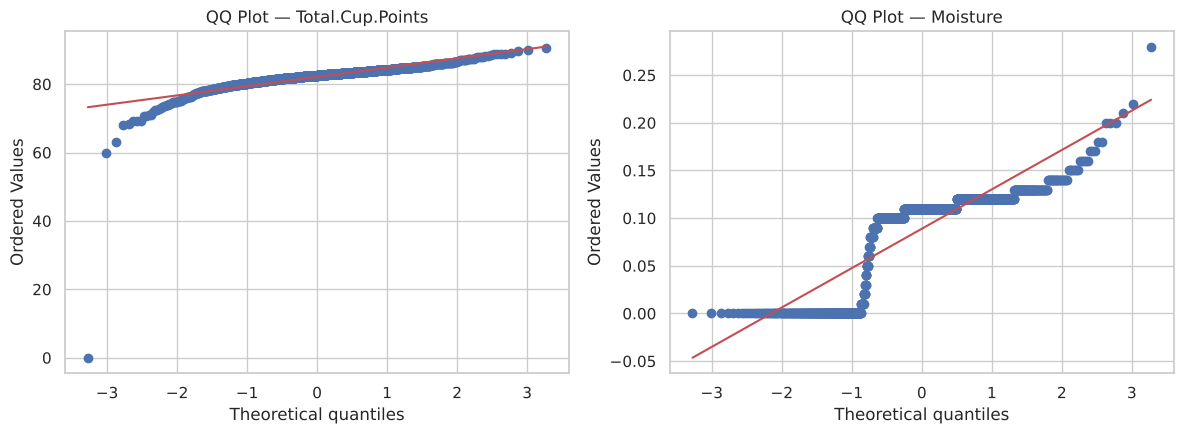

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
stats.probplot(df['Total.Cup.Points'], dist='norm', plot=axes[0])
axes[0].set_title('QQ Plot — Total.Cup.Points')
stats.probplot(df['Moisture'], dist='norm', plot=axes[1])
axes[1].set_title('QQ Plot — Moisture')
plt.tight_layout(); plt.show()

**Interpretasi:**
- Skor cupping sebagian besar berkumpul di rentang sempit (Aroma, Flavor, dll. sekitar 7–8; total sekitar 80–85).
- Boxplot memperlihatkan satu titik di **0** pada hampir semua atribut, berasal dari satu sampel yang semua skornya 0. Ini bukan kopi yang sangat buruk, melainkan **kesalahan input data**.
- `Uniformity`, `Clean.Cup`, dan `Sweetness` hampir selalu bernilai 10 (nilai maksimum), sehingga semua nilai di bawah 10 terlihat sebagai "outlier" di boxplot.
- QQ plot `Total.Cup.Points` lurus di tengah tetapi melenceng di ekor kiri → distribusi tidak normal sempurna karena ada nilai ekstrem rendah. QQ plot `Moisture` berbentuk tangga karena banyak sampel bernilai 0 (kemungkinan kadar air tidak diukur).

## 7. Identifikasi Kandidat Outlier dengan IQR

In [13]:
def outlier_iqr(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (series < batas_bawah) | (series > batas_atas)
    return mask, batas_bawah, batas_atas

kolom_numerik = skor + ['Moisture', 'Quakers', 'Category.One.Defects',
                        'Category.Two.Defects', 'Number.of.Bags', 'altitude_mean_meters']
hasil = []
for col in kolom_numerik:
    s = df[col].dropna()
    mask, bb, ba = outlier_iqr(s)
    hasil.append({'kolom': col, 'batas_bawah': round(bb, 2), 'batas_atas': round(ba, 2),
                  'jumlah_outlier': int(mask.sum()), 'persen': round(mask.mean() * 100, 2)})
pd.DataFrame(hasil).sort_values('persen', ascending=False)

,kolom,batas_bawah,batas_atas,jumlah_outlier,persen
11,Moisture,0.04,0.16,293,22.35
13,Category.One.Defects,0.00,0.00,200,15.26
6,Uniformity,10.00,10.00,183,13.96
7,Clean.Cup,10.00,10.00,117,8.92
12,Quakers,0.00,0.00,94,7.18
14,Category.Two.Defects,-6.00,10.00,94,7.17
8,Sweetness,10.00,10.00,93,7.09
2,Aftertaste,6.75,8.07,85,6.48
10,Total.Cup.Points,77.42,87.42,74,5.64
16,altitude_mean_meters,350.00,2350.00,61,5.63


In [14]:
# Lihat sampel dengan skor total paling rendah
df.nsmallest(3, 'Total.Cup.Points')[['Country.of.Origin', 'Aroma', 'Flavor', 'Acidity', 'Body', 'Total.Cup.Points']]

,Country.of.Origin,Aroma,Flavor,Acidity,Body,Total.Cup.Points
1310,Honduras,0.00,0.00,0.00,0.00,0.00
1309,Guatemala,7.50,6.67,7.67,7.33,59.83
1308,Nicaragua,7.25,6.58,6.25,6.42,63.08


In [15]:
# Ketinggian versi kolom bantu: ada yang ratusan ribu meter
df.nlargest(6, 'altitude_mean_meters')[['Country.of.Origin', 'Altitude', 'unit_of_measurement', 'altitude_mean_meters']]

,Country.of.Origin,Altitude,unit_of_measurement,altitude_mean_meters
896,Guatemala,190164,m,190164.0
1144,Guatemala,1901.64,m,190164.0
1040,Nicaragua,1100.00 mosl,m,110000.0
543,Brazil,11000 metros,m,11000.0
1098,Myanmar,4287,m,4287.0
840,Myanmar,4001,m,4001.0


**Interpretasi (outlier tidak otomatis dihapus):**
- **Skor total 0** (Honduras) → kesalahan input, **dihapus**.
- **Skor total 59,83** (Guatemala) → skornya rendah tapi wajar dan konsisten di semua atribut, jadi ini kopi yang memang kualitasnya buruk. **Dipertahankan**.
- **Ketinggian 190.164 m dan 110.000 m** → mustahil (Gunung Everest hanya ±8.849 m). Penyebabnya terlihat jelas: `"1901.64"` dan `"1100.00 mosl"` salah dibaca, titiknya hilang. Ini contoh bagus kenapa kita perlu mem-parsing teks sendiri dengan hati-hati.
- Outlier di `Uniformity`, `Clean.Cup`, `Sweetness`, dan jumlah cacat (`Defects`, `Quakers`) adalah **variasi alami**, bukan error. Dipertahankan.

## 8. Preprocessing

### 8.1 Menghapus kolom yang tidak berguna

In [16]:
kolom_hapus = [
    'Unnamed: 0',             # hanya nomor urut
    'Species',                # semuanya 'Arabica', hanya satu nilai
    'Owner.1',                # duplikat dari Owner
    'Lot.Number',             # ~80% missing
    'ICO.Number',             # kode administrasi, tidak relevan untuk analisis
    'Certification.Address',  # kode hash, tidak bermakna
    'Certification.Contact',  # kode hash, tidak bermakna
    'altitude_low_meters', 'altitude_high_meters',  # kolom bantu, diolah ulang sendiri
]
df = df.drop(columns=kolom_hapus)
print('Ukuran sekarang:', df.shape)

Ukuran sekarang: (1311, 35)


### 8.2 Merapikan nama kolom

In [17]:
df.columns = (df.columns.str.lower()
                        .str.replace('.', '_', regex=False)
                        .str.strip())
df = df.rename(columns={'country_of_origin': 'country'})
df.columns.tolist()

['owner',
 'country',
 'farm_name',
 'mill',
 'company',
 'altitude',
 'region',
 'producer',
 'number_of_bags',
 'bag_weight',
 'in_country_partner',
 'harvest_year',
 'grading_date',
 'variety',
 'processing_method',
 'aroma',
 'flavor',
 'aftertaste',
 'acidity',
 'body',
 'balance',
 'uniformity',
 'clean_cup',
 'sweetness',
 'cupper_points',
 'total_cup_points',
 'moisture',
 'category_one_defects',
 'quakers',
 'color',
 'category_two_defects',
 'expiration',
 'certification_body',
 'unit_of_measurement',
 'altitude_mean_meters']

### 8.3 Menghapus data error (skor 0)

In [18]:
print('Sebelum:', len(df))
df = df[df['total_cup_points'] > 0].reset_index(drop=True)
print('Sesudah:', len(df))

Sebelum: 1311
Sesudah: 1310


### 8.4 Membersihkan kolom `altitude` (bagian paling menantang)

Contoh variasi penulisan yang ditemukan:

In [19]:
df['altitude'].dropna().sample(20, random_state=7).tolist()

['650',
 '1600 msnm',
 '1750 msnm',
 '1500',
 '1250',
 '4300',
 '650',
 '900',
 '1.3',
 '3280',
 '1050',
 '1600',
 '1754',
 '1600',
 '5600-5760 metros',
 '1500',
 '518',
 '1600 - 1950 msnm',
 '900',
 '1565']

Aturan parsing yang dipakai:
1. Huruf `o` yang menempel di belakang angka diganti nol (`"12oo"` → 1200, salah ketik di data Meksiko).
2. Titik, koma, atau apostrof dianggap **pemisah ribuan** jika diikuti tepat 3 digit (`"1.300"`, `"1,300"`, `"1'500"` → 1300/1500). Selain itu titik adalah desimal (`"1901.64"` → 1901,64).
3. Jika dua angka dihubungkan tanda rentang (`-`, `~`, `a`, `to`, `thru`, `and`), misalnya `"1400-1900"`, `"1520m-2200m"`, atau `"de 1600 a 1950"`, ambil **rata-ratanya**. Jika tidak, ambil angka pertama saja. Contoh: `"1800 meters (5900 ft)"` → 1800, bukan rata-rata 1800 dan 5900.
4. Jika teks mengandung `ft`, `feet`, `pies`, `psn` (*pies sobre nivel*), atau satuan tercatat `ft`, nilai dikonversi ke meter (× 0,3048).
5. Angka desimal di bawah 5 (misalnya `"1.2"` atau `"1.65"`) diasumsikan ditulis dalam **kilometer** → dikali 1.000. Ini asumsi, karena ketinggian 1,2 meter mustahil untuk kebun kopi, sedangkan 1.200 m sangat umum.
6. Hasil di luar rentang masuk akal untuk kebun kopi (**100–3.500 m**) dianggap tidak valid → NaN.

In [20]:
SATUAN = r'\s*(?:m|mts|meters?|metros)?\.?\s*'
RANGE = (r'(\d+(?:\.\d+)?)' + SATUAN +
         r'(?:-|–|~|\ba\b|\bto\b|\bthru\b|\band\b)' + r'\s*(\d+(?:\.\d+)?)')

def parse_altitude(teks, satuan):
    if pd.isna(teks):
        return np.nan
    t = str(teks).lower()
    t = re.sub(r'(?<=\d)o+', lambda m: '0' * len(m.group()), t)   # '12oo' -> '1200'
    t = re.sub(r"(?<=\d)[.,'](?=\d{3}(?!\d))", '', t)    # hapus pemisah ribuan
    rentang = re.search(RANGE, t)
    if rentang:                                              # '1400-1900' -> rata-rata
        nilai = (float(rentang.group(1)) + float(rentang.group(2))) / 2
    else:
        angka = re.findall(r'\d+(?:\.\d+)?', t)
        if not angka:
            return np.nan
        nilai = float(angka[0])                              # ambil angka pertama
    if nilai < 5 and nilai != int(nilai):                    # '1.2' -> 1,2 km
        nilai *= 1000
    if re.search(r'ft|feet|pies|psn', t) or satuan == 'ft':
        nilai *= 0.3048                                      # feet -> meter
    return nilai

df['altitude_m'] = [parse_altitude(t, s) for t, s in zip(df['altitude'], df['unit_of_measurement'])]

tidak_wajar = ~df['altitude_m'].between(100, 3500) & df['altitude_m'].notna()
print('Nilai tidak wajar yang dijadikan NaN:', tidak_wajar.sum())
df.loc[tidak_wajar, ['country', 'altitude', 'altitude_m']]

Nilai tidak wajar yang dijadikan NaN: 22


,country,altitude,altitude_m
100,Kenya,-1,1.0
279,Brazil,1,1.0
442,"Tanzania, United Republic Of",16.8,16.8
481,Brazil,1,1.0
543,Brazil,11000 metros,11000.0
613,Brazil,1,1.0
683,Brazil,1,1.0
737,Brazil,1,1.0
761,Brazil,1,1.0
780,Brazil,1,1.0


**Interpretasi:** nilai seperti `"1"`, `"0"`, dan `"-1"` (banyak dari Brasil) kemungkinan adalah isian asal karena kolom wajib diisi. Nilai 3.800–4.300 dari Myanmar mungkin sebenarnya dalam feet, tetapi satuannya tercatat meter, jadi tidak bisa dipastikan. Semua nilai ini dijadikan NaN lalu diimputasi.

In [21]:
df.loc[tidak_wajar, 'altitude_m'] = np.nan

# Contoh hasil parsing
contoh = ['12oo', '1.300 msnm', 'de 1600 a 1950 msnm', '1520m-2200m', '2800 ft', '1901.64', '4500 psnm', '1800 meters (5900', '1.65', "approx. 1'500 metres"]
pd.DataFrame({'teks_asli': contoh, 'hasil_meter': [round(parse_altitude(c, 'm'), 1) for c in contoh]})

,teks_asli,hasil_meter
0,12oo,1200.0
1,1.300 msnm,1300.0
2,de 1600 a 1950 msnm,1775.0
3,1520m-2200m,1860.0
4,2800 ft,853.4
5,1901.64,1901.6
6,4500 psnm,1371.6
7,1800 meters (5900,1800.0
8,1.65,1650.0
9,approx. 1'500 metres,1500.0


### 8.5 Membersihkan `bag_weight` (kg dan lbs)
Satuan `lbs` dikonversi ke kg (× 0,4536). Nilai tanpa satuan (misalnya `"1"` atau `"6"`) tidak bisa dipastikan satuannya, jadi dibiarkan NaN.

In [22]:
def parse_bag_weight(teks):
    if pd.isna(teks):
        return np.nan
    t = str(teks).lower()
    angka = re.findall(r'\d+(?:\.\d+)?', t)
    if not angka:
        return np.nan
    nilai = float(angka[0])
    if 'kg' in t:          # '2 kg,lbs' dianggap kg (satuan pertama)
        return nilai
    if 'lb' in t:
        return round(nilai * 0.4536, 2)
    return np.nan          # satuan tidak diketahui

df['bag_weight_kg'] = df['bag_weight'].apply(parse_bag_weight)
df[['bag_weight', 'bag_weight_kg']].drop_duplicates().head(10)

,bag_weight,bag_weight_kg
0,60 kg,60.00
2,1,NaN
5,30 kg,30.00
6,69 kg,69.00
11,1 kg,1.00
16,"2 kg,lbs",2.00
17,6,NaN
21,3 lbs,1.36
29,50 kg,50.00
33,2 lbs,0.91


### 8.6 Membersihkan `harvest_year` dan kolom tanggal
- Tanggal seperti `"April 4th, 2015"` diubah menjadi tipe `datetime`. Spasi/baris baru tersembunyi di ujung teks dibuang (ada 2 tanggal yang diakhiri `\n`), lalu akhiran *st/nd/rd/th* dihapus.
- Tahun panen diambil dari tahun 4 digit pertama (`"2013/2014"` → 2013). Nilai yang tidak bisa dibaca (`"Mayo a Julio"`, `"TEST"`, `"4T/10"`) **diisi dengan tahun grading**, karena kopi biasanya dinilai di tahun panen yang sama atau setelahnya.

In [23]:
def ke_tanggal(s):
    return pd.to_datetime(s.str.strip().str.replace(r'(\d)(st|nd|rd|th)', r'\1', regex=True),
                          format='%B %d, %Y', errors='coerce')

df['grading_date'] = ke_tanggal(df['grading_date'])
df['expiration'] = ke_tanggal(df['expiration'])

df['harvest_year_clean'] = (df['harvest_year'].astype(str)
                              .str.extract(r'((?:19|20)\d{2})')[0]
                              .astype(float))
tidak_terbaca = df['harvest_year'].notna() & df['harvest_year_clean'].isna()
print('Tahun panen tidak terbaca:', df.loc[tidak_terbaca, 'harvest_year'].unique())

df['harvest_year_clean'] = df['harvest_year_clean'].fillna(df['grading_date'].dt.year).astype(int)
df['harvest_year_clean'].value_counts().sort_index()

Tahun panen tidak terbaca: <StringArray>
[           'May-August',                   'mmm',                  'TEST',
                 '4T/10', 'January Through April',    'August to December',
          'Mayo a Julio',         'Abril - Julio',            '08/09 crop']
Length: 9, dtype: str


harvest_year_clean
2009     20
2010     46
2011     69
2012    352
2013    199
2014    245
2015    153
2016    133
2017     88
2018      5
Name: count, dtype: int64

### 8.7 Standarisasi nama negara

In [24]:
df['country'] = (df['country'].str.strip()
                   .replace({'Tanzania, United Republic Of': 'Tanzania',
                             'Cote d?Ivoire': "Cote d'Ivoire"}))
df['country'].value_counts().head(10)

country
Mexico                    236
Colombia                  183
Guatemala                 181
Brazil                    132
Taiwan                     75
United States (Hawaii)     73
Honduras                   52
Costa Rica                 51
Ethiopia                   44
Tanzania                   40
Name: count, dtype: int64

### 8.8 Menangani missing values
| Kolom | Strategi | Alasan |
|---|---|---|
| Kolom identitas (`farm_name`, `mill`, `company`, `producer`, `region`, `owner`, dll.) | isi `"Unknown"` | kosong = tidak dicantumkan, bukan error |
| `variety`, `processing_method`, `color` | isi `"Unknown"` | kategori; mengisi dengan modus akan membuat data bias |
| `altitude_m` | median **per negara**, lalu median keseluruhan | ketinggian sangat bergantung pada negara asal |
| `quakers` | isi 0 (modus) | hanya 1 data kosong |

In [25]:
kategori = df.select_dtypes(include=['object', 'string']).columns.drop(['altitude', 'bag_weight', 'harvest_year'])
df[kategori] = df[kategori].fillna('Unknown')

df['altitude_imputed'] = df['altitude_m'].isna().astype(int)   # tandai data hasil imputasi
df['altitude_m'] = df['altitude_m'].fillna(df.groupby('country')['altitude_m'].transform('median'))
df['altitude_m'] = df['altitude_m'].fillna(df['altitude_m'].median())

df['quakers'] = df['quakers'].fillna(0)

print('Ketinggian yang diimputasi:', df['altitude_imputed'].sum())

Ketinggian yang diimputasi: 248


### 8.9 Encoding variabel kategorikal

In [26]:
df_encoded = pd.get_dummies(df, columns=['processing_method', 'color'], prefix=['process', 'color'], dtype=int)
[c for c in df_encoded.columns if c.startswith(('process_', 'color_'))]

['process_Natural / Dry',
 'process_Other',
 'process_Pulped natural / honey',
 'process_Semi-washed / Semi-pulped',
 'process_Unknown',
 'process_Washed / Wet',
 'color_Blue-Green',
 'color_Bluish-Green',
 'color_Green',
 'color_Unknown']

### 8.10 Scaling fitur numerik (opsional, untuk keperluan modeling)

In [27]:
fitur = ['aroma', 'flavor', 'aftertaste', 'acidity', 'body', 'balance', 'altitude_m', 'moisture']
scaler = StandardScaler()
df_scaled = df_encoded.copy()
df_scaled[fitur] = scaler.fit_transform(df_scaled[fitur])
df_scaled[fitur].describe().loc[['mean', 'std']].round(3)

,aroma,flavor,aftertaste,acidity,body,balance,altitude_m,moisture
mean,0.0,0.0,-0.0,-0.0,0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 9. Validasi Hasil Preprocessing

In [28]:
# 1. Tidak ada lagi missing values di kolom hasil olahan
kolom_final = ['country', 'variety', 'processing_method', 'color', 'altitude_m',
               'harvest_year_clean', 'quakers', 'total_cup_points']
df[kolom_final].isna().sum()

country               0
variety               0
processing_method     0
color                 0
altitude_m            0
harvest_year_clean    0
quakers               0
total_cup_points      0
dtype: int64

In [29]:
# 2. Tipe data sudah sesuai
df[['altitude_m', 'bag_weight_kg', 'harvest_year_clean', 'grading_date', 'expiration']].dtypes

altitude_m                   float64
bag_weight_kg                float64
harvest_year_clean             int64
grading_date          datetime64[us]
expiration            datetime64[us]
dtype: object

In [30]:
# 3. Bandingkan hasil parsing ketinggian kita dengan kolom bantu bawaan dataset
banding = df[['altitude', 'altitude_mean_meters', 'altitude_m', 'altitude_imputed']].copy()
banding = banding[(banding['altitude_imputed'] == 0) & banding['altitude_mean_meters'].notna()]
selisih = (banding['altitude_m'] - banding['altitude_mean_meters']).abs()
print(f'Hasil sama persis (selisih < 1 m): {(selisih < 1).sum()} dari {len(banding)} baris')
print('Baris yang berbeda:')
banding[selisih >= 1]

Hasil sama persis (selisih < 1 m): 1047 dari 1062 baris
Baris yang berbeda:


,altitude,altitude_mean_meters,altitude_m,altitude_imputed
41,1.2,12.0,1200.00,0
42,1.2,12.0,1200.00,0
224,approx. 1'500 metres a.s.l.,250.5,1500.00,0
451,1400-1900 psn,1650.0,502.92,0
452,approx.1'500 metres a.s.l.,250.5,1500.00,0
595,1.65,165.0,1650.00,0
628,1800 meters (5900,3850.0,1800.00,0
785,1.3,13.0,1300.00,0
898,1.3,13.0,1300.00,0
930,1.25,125.0,1250.00,0


**Interpretasi:** hasil parsing kita sama dengan kolom bawaan di hampir semua baris. Sebagian besar perbedaannya justru menunjukkan kolom bawaan yang keliru: `"1901.64"` dan `"1100.00 mosl"` dibaca 100 kali lebih besar, `"1.2"` dibaca 12 m (kita baca 1.200 m), dan `"1800 meters (5900"` dibaca sebagai rentang. Satu kasus yang ambigu adalah `"1400-1900 psn"`: menurut aturan kita, `psn` berarti *pies* (feet), sehingga hasilnya sekitar 503 m, sedangkan kolom bawaan menganggapnya meter. Kasus seperti ini layak disebutkan dalam laporan sebagai keterbatasan.

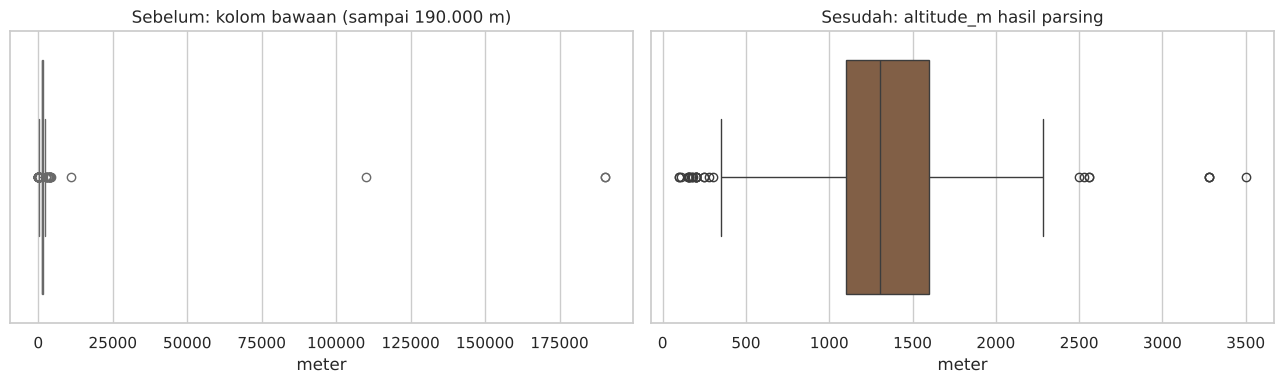

In [31]:
# 4. Distribusi ketinggian sebelum vs sesudah dibersihkan
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(x=df_raw['altitude_mean_meters'], ax=axes[0], color='#D2B48C')
axes[0].set_title('Sebelum: kolom bawaan (sampai 190.000 m)')
axes[0].set_xlabel('meter')
sns.boxplot(x=df['altitude_m'], ax=axes[1], color='#8B5E3C')
axes[1].set_title('Sesudah: altitude_m hasil parsing')
axes[1].set_xlabel('meter')
plt.tight_layout(); plt.show()

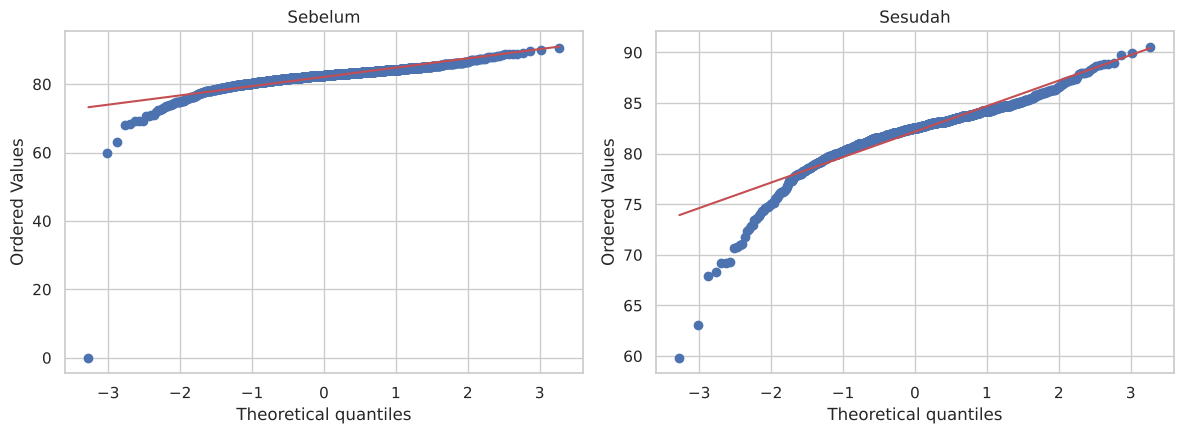

In [32]:
# 5. QQ plot skor total setelah sampel skor 0 dihapus
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
stats.probplot(df_raw['Total.Cup.Points'], dist='norm', plot=axes[0])
axes[0].set_title('Sebelum')
stats.probplot(df['total_cup_points'], dist='norm', plot=axes[1])
axes[1].set_title('Sesudah')
plt.tight_layout(); plt.show()

In [33]:
print('Ukuran awal :', df_raw.shape)
print('Ukuran akhir:', df.shape)

Ukuran awal : (1311, 44)
Ukuran akhir: (1310, 39)


## 10. Insight Singkat dari Data Bersih

In [34]:
top = (df.groupby('country')
         .agg(jumlah_sampel=('total_cup_points', 'size'), rata_skor=('total_cup_points', 'mean'))
         .query('jumlah_sampel >= 10')
         .sort_values('rata_skor', ascending=False)
         .round(2))
top

,jumlah_sampel,rata_skor
country,,
Ethiopia,44,85.48
Kenya,25,84.31
Uganda,26,84.05
Colombia,183,83.11
El Salvador,21,83.05
China,16,82.93
Costa Rica,51,82.79
Thailand,32,82.57
Indonesia,20,82.57


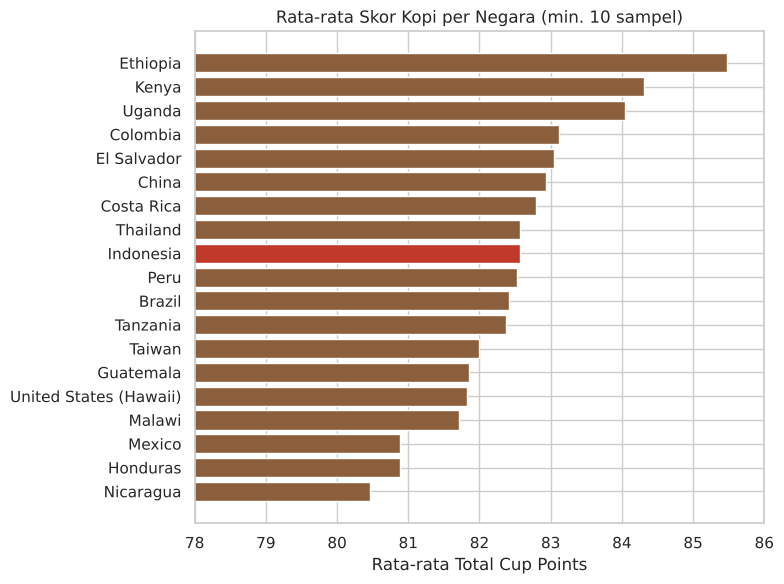

In [35]:
fig, ax = plt.subplots(figsize=(8, 6))
warna = ['#C0392B' if n == 'Indonesia' else '#8B5E3C' for n in top.index]
ax.barh(top.index[::-1], top['rata_skor'][::-1], color=warna[::-1])
ax.set_xlim(78, 86)
ax.set_xlabel('Rata-rata Total Cup Points')
ax.set_title('Rata-rata Skor Kopi per Negara (min. 10 sampel)')
plt.tight_layout(); plt.show()

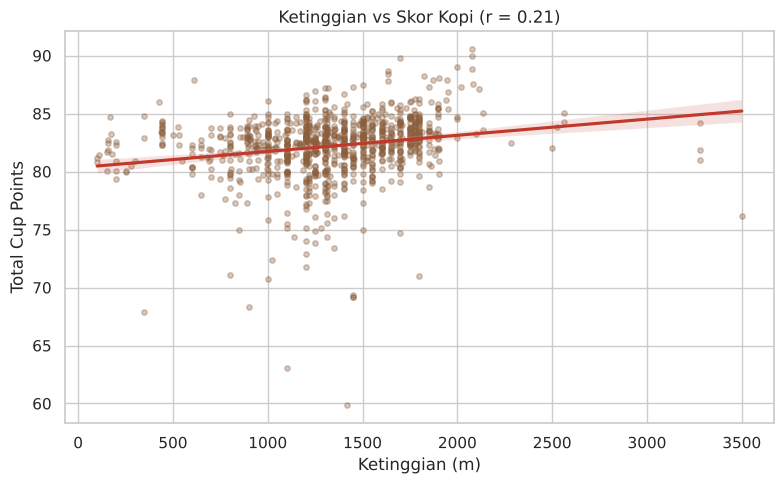

In [36]:
fig, ax = plt.subplots(figsize=(8, 5))
asli = df[df['altitude_imputed'] == 0]
sns.regplot(data=asli, x='altitude_m', y='total_cup_points',
            scatter_kws={'alpha': 0.35, 's': 15, 'color': '#8B5E3C'}, line_kws={'color': '#C0392B'}, ax=ax)
r = asli[['altitude_m', 'total_cup_points']].corr().iloc[0, 1]
ax.set_title(f'Ketinggian vs Skor Kopi (r = {r:.2f})')
ax.set_xlabel('Ketinggian (m)'); ax.set_ylabel('Total Cup Points')
plt.tight_layout(); plt.show()

## 11. Menyimpan Data Bersih

In [37]:
kolom_simpan = ['country', 'region', 'farm_name', 'company', 'producer', 'variety', 'processing_method', 'color',
                'altitude_m', 'altitude_imputed', 'harvest_year_clean', 'grading_date', 'bag_weight_kg', 'number_of_bags',
                'aroma', 'flavor', 'aftertaste', 'acidity', 'body', 'balance', 'uniformity', 'clean_cup',
                'sweetness', 'cupper_points', 'total_cup_points', 'moisture', 'category_one_defects',
                'quakers', 'category_two_defects']
df[kolom_simpan].to_csv('coffee_quality_clean.csv', index=False)
print('Tersimpan: coffee_quality_clean.csv', df[kolom_simpan].shape)

Tersimpan: coffee_quality_clean.csv (1310, 29)


## 12. Kesimpulan

1. Dataset awal berisi **1.311 baris × 44 kolom** dengan banyak masalah kualitas: missing values (sampai ~80% di `Lot.Number`), kolom duplikat (`Owner.1`), kolom bernilai tunggal (`Species`), dan kolom angka/tanggal yang tersimpan sebagai teks.
2. Tantangan utama ada di kolom **`Altitude`**: puluhan variasi format (rentang, satuan feet/meter, bahasa Spanyol, pemisah ribuan). Parsing yang hati-hati berhasil memperbaiki nilai mustahil seperti 190.164 m yang muncul di kolom bawaan dataset.
3. Outlier **tidak dihapus otomatis**. Hanya sampel dengan skor 0 (jelas error input) yang dihapus; skor rendah yang wajar dan variasi cacat biji tetap dipertahankan.
4. Missing values ditangani sesuai konteks: kategori diisi `"Unknown"`, ketinggian diisi median per negara (dengan penanda `altitude_imputed`), tahun panen yang tidak terbaca diisi tahun grading.
5. Data bersih (`coffee_quality_clean.csv`) siap dipakai untuk analisis lanjutan atau modeling, misalnya memprediksi skor kopi dari ketinggian, varietas, dan metode proses.